# Can we predict a negative review? (Olist)

**Goal:** predict if an order will get a negative review (score 1 or 2), using only information we know **before** the review.

**Why:** if Olist knows which customers are at risk, it can act early, for example send an apology email or a coupon.

**Target:** `is_negative` (1 = negative review, 0 = not negative). Only 12.3% of orders are negative, so the two classes are not balanced.

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

## Plan

All steps are inside one scikit-learn **Pipeline**:

```
Pipeline
 ├─ ColumnTransformer (prepare the data)
 │   ├─ numeric columns  → StandardScaler
 │   └─ text columns     → OneHotEncoder
 └─ Model
```

Models I tried: Logistic Regression (baseline), Random Forest, Gradient Boosting.

I compare them with **precision, recall and F1** for the negative class:
- **Recall:** of all unhappy customers, how many does the model find?
- **Precision:** of all orders the model flags as negative, how many are really negative?
- **F1:** one number that balances precision and recall.

## 1. Load the data

I use the clean table from the EDA notebook: one row per order, only orders with one seller (94,563 orders).

In [ ]:
df = pd.read_csv('../olist_dashboard.csv')
df.head()

,order_id,late_day,review_score,customer_id,order_purchase_timestamp,order_estimated_delivery_date,order_delivered_customer_date,customer_state,customer_zip_code_prefix,customer_city,...,product_id,price,freight_value,product_category_name,product_category_name_english,rating,is_late,is_negative,is_different_state,late_day_cat
0,031a7dab65c3430d325ad35ab8a95277,-22,1,e01e9c45a4dc4ef2cbfb266fd92afaab,2018-06-21 22:17:19,2018-07-19,2018-06-27 16:18:37,PR,83420,quatro barras,...,18fa9cc25ea8b54f32d029f261673c0f,109.9,18.82,construcao_ferramentas_construcao,construction_tools_construction,negative,0,1,0,on time
1,0068468c453d28c8ef3fd089e50a5847,-6,5,6460086b02eadee2bb54c83af13698b0,2017-11-24 22:25:25,2017-12-20,2017-12-14 11:47:13,RJ,26272,nova iguacu,...,2f763ba79d9cd987b2034aac7ceffe06,469.0,20.85,eletronicos,electronics,very_positive,0,0,1,on time
2,035c01a45e289b155db4e47cf39b29d3,-5,5,d68f9c633f9ab44265b54f3792fcbe71,2018-08-06 22:01:08,2018-08-28,2018-08-23 15:03:10,SP,13077,campinas,...,656e0eca68dcecf6a31b8ececfabe3e8,79.9,13.90,informatica_acessorios,computers_accessories,very_positive,0,0,1,on time
3,016befe103ce7c9e5b1b7ef359777eea,-10,5,15f3f60c0575a9f2a7d5434f7b8a7692,2017-09-03 10:11:52,2017-09-21,2017-09-11 14:36:51,SP,12490,sao bento do sapucai,...,6c321ed0f47858a8650f4104771224b5,49.0,11.85,relogios_presentes,watches_gifts,very_positive,0,0,0,on time
4,13b825fdc28948500cfc7a03eb975fbc,-19,5,669b06cabc9d39c1bcc52e6889e1318d,2018-02-13 11:05:56,2018-03-12,2018-02-21 20:09:22,SP,14930,boa esperanca do sul,...,e9f4a2b16f44a27e454037659cceb20f,31.0,11.85,automotivo,auto,very_positive,0,0,0,on time


## 2. Check the text columns with many values

Some text columns have a lot of different values. Too many values make the model slow and noisy.

In [3]:
df['customer_city'].value_counts()

customer_city
sao paulo            14728
rio de janeiro        6469
belo horizonte        2651
brasilia              2037
curitiba              1461
                     ...  
unistalda                1
ipiranga do norte        1
marilac                  1
cerro grande             1
caldas brandao           1
Name: count, Length: 4075, dtype: int64

In [4]:
df['seller_id'].unique()

array(['0b35c634521043bf4b47e21547b99ab5',
       '822bad9bc42b51213ba522fe87b7ab5d',
       '5f67c6082caacb26e431a7b17940cece', ...,
       '3d2400ac620cffa23ac81bd192f7f555',
       'e908c0f3646e8b60375734a350d95d71',
       '8936ba0de1073ee888cb3185ae5dc661'], shape=(2944,), dtype=object)

**Result:** 4,075 customer cities and 2,944 sellers.
- Cities: too many, and many have only 1 order → I do not use them (state is enough).
- Sellers: the EDA showed that some sellers are much worse than others → I keep them, but only sellers with 50+ orders get their own column (see step 6).

Check the data types. The date columns are text (`object`), so I need to convert them to dates.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94563 entries, 0 to 94562
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       94563 non-null  object 
 1   late_day                       94563 non-null  int64  
 2   review_score                   94563 non-null  int64  
 3   customer_id                    94563 non-null  object 
 4   order_purchase_timestamp       94563 non-null  object 
 5   order_estimated_delivery_date  94563 non-null  object 
 6   order_delivered_customer_date  94563 non-null  object 
 7   customer_state                 94563 non-null  object 
 8   customer_zip_code_prefix       94563 non-null  int64  
 9   customer_city                  94563 non-null  object 
 10  seller_id                      94563 non-null  object 
 11  seller_city                    94563 non-null  object 
 12  seller_state                   94563 non-null 

## 3. New features from the dates

- `promised_days`: how many days Olist promised for delivery (estimated date − purchase date)
- `delivery_days`: how many days the delivery really took (delivered date − purchase date)

In [7]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'])
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'])

In [8]:
df['promised_days']= (df['order_estimated_delivery_date']-df['order_purchase_timestamp']).dt.days
df['delivery_days']= (df['order_delivered_customer_date']-df['order_purchase_timestamp']).dt.days

In [9]:
df[['promised_days','delivery_days']].describe()

,promised_days,delivery_days
count,94563.000000,94563.000000
mean,23.345769,12.097702
std,8.762515,9.498686
min,2.000000,0.000000
25%,18.000000,6.000000
50%,23.000000,10.000000
75%,28.000000,15.000000
max,155.000000,208.000000


**Result:** Olist promises about **23 days** on average, but delivery takes only about **12 days**. So most orders arrive early. This explains why only 6.7% of orders are late.

## 4. Choose the features

I only use information that is known **before** the review.

| Type | Columns |
|---|---|
| Numeric | late_day, is_late, price, freight_value, is_different_state, promised_days, delivery_days |
| Text (one-hot) | customer_state, seller_state, product_category_name_english, seller_id |
| Target | is_negative |

**Not used:**
- `review_score` and `rating`: `is_negative` comes from them, so the model would see the answer (**data leakage**)
- IDs (order_id, customer_id, product_id): every order has a new ID, the model cannot learn from them
- Cities and zip codes: too many values. The state gives enough location information
- `late_day_cat`: same information as `late_day`
- `product_category_name`: same as the English name
- Raw dates: the model cannot use them directly, so I use `promised_days` and `delivery_days` instead

I keep both `late_day` (how many days) and `is_late` (late or not), because the EDA showed a big jump in negative reviews when an order becomes late.

In [12]:
numeric_features= ['late_day','price','freight_value','is_late','is_different_state','promised_days','delivery_days']

In [13]:
categorical_features=['customer_state','seller_id','seller_state','product_category_name_english']

In [14]:
X = df[numeric_features+categorical_features]
y= df['is_negative']
print(X.shape)
print(y.shape)

(94563, 11)
(94563,)


## 5. Train / test split

- 80% of the orders to train the model, 20% to test it on new data
- `stratify=y` keeps the same share of negative reviews (12.3%) in train and test

In [15]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train,y_test=train_test_split(X , y , test_size=0.2,random_state=42,stratify=y)

In [16]:
y_train.mean()

np.float64(0.12342366159947125)

In [17]:
y_test.mean()

np.float64(0.12340718024639137)

Train and test both have 12.3% negative reviews. ✓

## 6. Prepare the data (ColumnTransformer)

- **StandardScaler:** puts the numeric columns on the same scale (price can be 1,000, but `is_late` is only 0 or 1)
- **OneHotEncoder:** turns text into 0/1 columns
  - `min_frequency=50`: sellers or categories with fewer than 50 orders go into one "other" group (about 400 big sellers keep their own column)
  - `handle_unknown='infrequent_if_exist'`: a new seller or category (for example in the app) also goes into "other", so there is no error

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [19]:
preprocessor=ColumnTransformer(transformers=[('num',StandardScaler(),numeric_features),
('cat',OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50),categorical_features)])

## 7. Baseline model: Logistic Regression

`class_weight='balanced'`: only 12% of orders are negative. Without this, the model could say "not negative" for every order and still get 88% accuracy, but it would find zero unhappy customers. With `balanced`, mistakes on negative orders count more.

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [21]:



pipe = Pipeline(steps=[('preprocessor', preprocessor),('model', LogisticRegression(class_weight='balanced', max_iter=1000))
])

In [22]:
pipe.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [23]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
y_pred = pipe.predict(X_test)


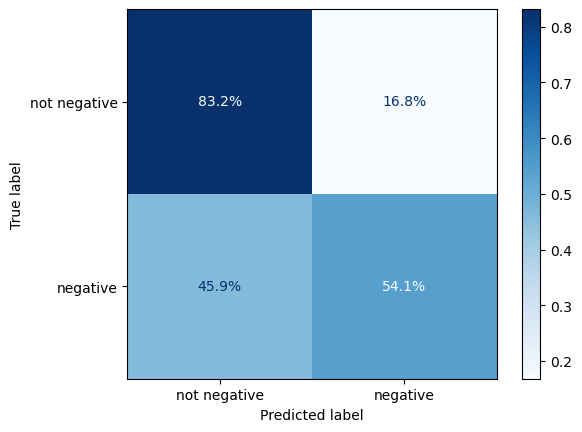

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
display_labels=['not negative', 'negative'],
cmap='Blues',
normalize='true',values_format='.1%')
plt.show()

In [26]:
print(classification_report(y_test, y_pred, target_names=['not negative', 'negative']))
   
y_proba = pipe.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))  
   

              precision    recall  f1-score   support

not negative       0.93      0.83      0.88     16579
    negative       0.31      0.54      0.40      2334

    accuracy                           0.80     18913
   macro avg       0.62      0.69      0.64     18913
weighted avg       0.85      0.80      0.82     18913

ROC-AUC: 0.742


**Results (negative class, test set):**
- Recall 0.54: the model finds 54% of unhappy customers
- Precision 0.31: 31% of the orders it flags are really negative (a random guess would give 12%)
- F1 0.40

**Accuracy** is 0.80, lower than "always say not negative" (0.88). This is OK: that lazy model would find zero unhappy customers.

**Takeaway:** better than random, but far from perfect. This fits the EDA: most negative reviews are on-time orders, and their reasons (product quality, wrong size...) are not in the data.

## 8. Random Forest

Many decision trees that vote together.

In [27]:
from sklearn.ensemble import RandomForestClassifier
pipe_rf = Pipeline(steps=[('preprocessor', preprocessor),('model', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1))])
pipe_rf.fit(X_train,y_train)
y_pred = pipe_rf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=['not negative', 'negative']))
   
y_proba = pipe_rf.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))  


              precision    recall  f1-score   support

not negative       0.91      0.98      0.94     16579
    negative       0.70      0.31      0.43      2334

    accuracy                           0.90     18913
   macro avg       0.80      0.65      0.69     18913
weighted avg       0.88      0.90      0.88     18913

ROC-AUC: 0.717


In [28]:
y_proba_train = pipe_rf.predict_proba(X_train)[:, 1]
print("Train ROC-AUC:", round(roc_auc_score(y_train, y_proba_train), 3))

Train ROC-AUC: 1.0


**Results:** precision 0.70, recall 0.31, F1 0.43. Random Forest flags fewer orders, but when it does, it is often right.

**Overfitting check:** I compare the score on the train data and on the test data. Here I use ROC-AUC, a score from 0.5 (random) to 1.0 (perfect).

| | ROC-AUC |
|---|---|
| Train | 1.000 |
| Test | 0.717 |

The model **memorized** the train data. With default settings, each tree grows until every leaf has only one order, so it does not work as well on new orders.

**Next step:** make the trees smaller.

## 9. Random Forest with smaller trees

- `max_depth=10`: each tree can ask at most 10 questions
- `min_samples_leaf=20`: each final group (leaf) must have at least 20 orders

This forces the trees to learn general rules, not single orders.

In [29]:
pipe_rf2 = Pipeline(steps=[('preprocessor', preprocessor),('model', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1,max_depth=10,min_samples_leaf=20))])
pipe_rf2.fit(X_train,y_train)
y_pred = pipe_rf2.predict(X_test)
print(classification_report(y_test, y_pred, target_names=['not negative', 'negative']))
   
y_proba = pipe_rf2.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3)) 

              precision    recall  f1-score   support

not negative       0.92      0.92      0.92     16579
    negative       0.43      0.42      0.43      2334

    accuracy                           0.86     18913
   macro avg       0.68      0.67      0.67     18913
weighted avg       0.86      0.86      0.86     18913

ROC-AUC: 0.719


In [30]:
y_proba_train = pipe_rf2.predict_proba(X_train)[:, 1]
print("Train ROC-AUC:", round(roc_auc_score(y_train, y_proba_train), 3))

Train ROC-AUC: 0.738


**Results:** precision 0.43, recall 0.42, F1 0.43.

| Model | Train AUC | Test AUC |
|---|---|---|
| Random Forest (default) | 1.000 | 0.717 |
| Random Forest (smaller trees) | 0.738 | 0.719 |

**Takeaway:** the overfitting is gone (train and test are close now), but the test score did not get better. So the limit is the **data**, not the model.

## 10. Tuning Logistic Regression

`C` controls how strict the model is: a small C gives a simpler model. I test C = 0.01, 0.1, 1, 10 (1 is the default).

**GridSearchCV** splits the train data into 5 parts and tests each value 5 times. The test data stays untouched until the end. Here the best C is chosen by ROC-AUC (a score from 0.5 = random to 1.0 = perfect).

In [31]:
from sklearn.model_selection import GridSearchCV
param_grid = {'model__C':[0.01, 0.1, 1, 10]}
grid = GridSearchCV(pipe,param_grid,cv=5,scoring='roc_auc',n_jobs=-1 )
grid.fit(X_train,y_train)
print("Best C:", grid.best_params_)
print("Best CV AUC:", round(grid.best_score_, 3))

Best C: {'model__C': 0.1}
Best CV AUC: 0.737


In [32]:
best_model = grid.best_estimator_

y_pred_best = best_model.predict(X_test)
print(classification_report(y_test, y_pred_best, target_names=['not negative', 'negative']))

y_proba_best = best_model.predict_proba(X_test)[:, 1]
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_proba_best), 3))

              precision    recall  f1-score   support

not negative       0.93      0.85      0.89     16579
    negative       0.33      0.52      0.40      2334

    accuracy                           0.81     18913
   macro avg       0.63      0.68      0.64     18913
weighted avg       0.85      0.81      0.83     18913

Test ROC-AUC: 0.743


**Best C:** 0.1, a bit simpler than the default.

**Test results:** precision 0.33, recall 0.52, F1 0.40. Almost the same as before: tuning helps only a little.

## 11. Gradient Boosting

- Random Forest builds many trees **independently**.
- Gradient Boosting builds trees **one after another**: each new tree tries to fix the mistakes of the trees before.

`HistGradientBoostingClassifier` does not accept sparse data (a table full of 0s stored in a special way), so I make a second preprocessor with `sparse_output=False`.

In [33]:
from sklearn.ensemble import HistGradientBoostingClassifier


preprocessor_dense = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist',
                          min_frequency=50,
                          sparse_output=False), categorical_features)
])

pipe_hgb = Pipeline(steps=[
    ('preprocessor', preprocessor_dense),
    ('model', HistGradientBoostingClassifier(class_weight='balanced', random_state=42))
])

pipe_hgb.fit(X_train, y_train)

y_pred_hgb = pipe_hgb.predict(X_test)
print(classification_report(y_test, y_pred_hgb, target_names=['not negative', 'negative']))

              precision    recall  f1-score   support

not negative       0.92      0.89      0.90     16579
    negative       0.37      0.47      0.41      2334

    accuracy                           0.83     18913
   macro avg       0.65      0.68      0.66     18913
weighted avg       0.85      0.83      0.84     18913



**Test results (negative class):** precision 0.37, recall 0.47, F1 0.41.

**Overfitting check:** same report, but on the train data.

In [34]:
y_pred_hgb_train = pipe_hgb.predict(X_train)
print(classification_report(y_train, y_pred_hgb_train, target_names=['not negative', 'negative']))

              precision    recall  f1-score   support

not negative       0.93      0.89      0.91     66313
    negative       0.39      0.51      0.44      9337

    accuracy                           0.84     75650
   macro avg       0.66      0.70      0.68     75650
weighted avg       0.86      0.84      0.85     75650



**Result:** F1 on train is 0.44, on test 0.41. Very close, so there is **no overfitting**.

## 12. Tuning Gradient Boosting

I tune with **F1**, because I want a balance between precision and recall.

- `learning_rate`: how much each new tree corrects the trees before (default 0.1)
- `max_leaf_nodes`: maximum number of leaves per tree (default 31)
- `min_samples_leaf`: minimum number of orders per leaf (default 20)

2 × 2 × 2 = 8 combinations, each tested 3 times.

In [35]:
param_grid_hgb = {
    'model__learning_rate': [0.05, 0.1],
    'model__max_leaf_nodes': [15, 31],
    'model__min_samples_leaf': [20, 50]
}

grid_hgb = GridSearchCV(
    pipe_hgb,
    param_grid_hgb,
    cv=3,              # 3 instead of 5, to make it faster
    scoring='f1',      # choose the best model by F1
    n_jobs=2           # not -1: uses less memory
)

grid_hgb.fit(X_train, y_train)

print("Best params:", grid_hgb.best_params_)
print("Best CV F1:", round(grid_hgb.best_score_, 3))

Best params: {'model__learning_rate': 0.05, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 20}
Best CV F1: 0.413


**Best:** learning_rate 0.05, max_leaf_nodes 15, min_samples_leaf 20. Simpler trees work better.

(Two of the best values are the smallest in my list, so even smaller values could be tested later.)

In [36]:
best_hgb = grid_hgb.best_estimator_

y_pred_best_hgb = best_hgb.predict(X_test)
print(classification_report(y_test, y_pred_best_hgb, target_names=['not negative', 'negative']))

              precision    recall  f1-score   support

not negative       0.92      0.89      0.91     16579
    negative       0.38      0.46      0.42      2334

    accuracy                           0.84     18913
   macro avg       0.65      0.68      0.66     18913
weighted avg       0.86      0.84      0.85     18913



## 13. Final model: Gradient Boosting (tuned)

**Test results (negative class):** precision 0.38, recall 0.46, F1 0.42.

| Model | Precision | Recall | F1 |
|---|---|---|---|
| Logistic Regression (tuned) | 0.33 | 0.52 | 0.40 |
| Random Forest (smaller trees) | 0.43 | 0.42 | 0.43 |
| **Gradient Boosting (tuned)** | **0.38** | **0.46** | **0.42** |

**Why I chose Gradient Boosting:**
- Olist could send an automatic apology email or a coupon to customers at risk. This is cheap, so finding many unhappy customers (**recall**) is important.
- But sending coupons to too many happy customers costs money (**precision**).
- Gradient Boosting gives a good balance: it finds almost half of the unhappy customers, with better precision than Logistic Regression. It is also fast (about 10 seconds) and has no overfitting.
- Random Forest has a slightly higher F1, but lower recall, and it is much slower (about 1 minute).

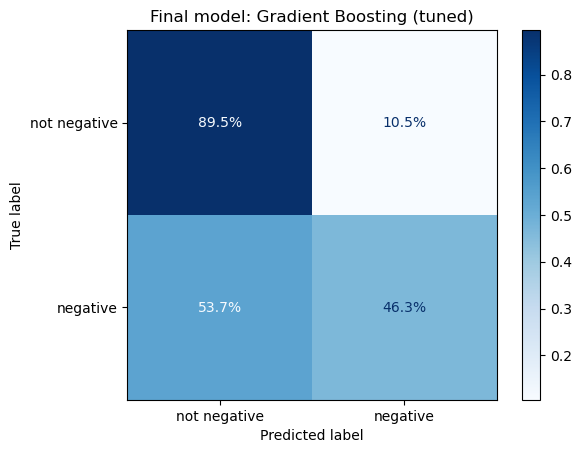

In [37]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best_hgb,
    display_labels=['not negative', 'negative'],
    cmap='Blues', normalize='true', values_format='.1%')
plt.title('Final model: Gradient Boosting (tuned)')
plt.show()

**Confusion matrix (final model, test set):**
- Of all unhappy customers, the model finds 46.3% (recall).
- Of all happy customers, 89.5% are correctly marked as low risk. Only 10.5% get a "high risk" flag by mistake, so few coupons would be wasted.

## 14. What drives the model? (feature importance)

**Question:** which features does the model use most to find negative reviews: delivery, or seller and product?

**Method:** permutation importance.
1. Measure F1 on the test data.
2. Shuffle one column, so it has no meaning anymore.
3. Measure F1 again.
4. If F1 drops a lot, the column was important. If F1 stays almost the same, the column was not important.

This is done for each of the 11 original columns (not the one-hot columns), so the result is easy to read.

In [38]:
from sklearn.inspection import permutation_importance
# shuffle each column 5 times and measure how much F1 drops
result= permutation_importance(best_hgb,X_test,y_test,
                               scoring='f1',     # same metric as our model choice
                                n_repeats=5,      # 5 shuffles per column, then the average
                                random_state=42,  # same result every time
                                n_jobs=2)         # not -1: uses less memory
# put the average drop next to each column name, most important first
importance =pd.Series(result.importances_mean, index=X_test.columns)
importance.sort_values(ascending=False)

delivery_days                    0.079585
late_day                         0.054872
freight_value                    0.020647
seller_id                        0.012548
price                            0.002356
product_category_name_english    0.002326
customer_state                   0.001767
seller_state                     0.001129
promised_days                    0.000549
is_late                          0.000000
is_different_state               0.000000
dtype: float64

**Result (drop in F1 when a column is shuffled):**

| Feature | Importance | Group |
|---|---|---|
| delivery_days | 0.080 | delivery |
| late_day | 0.055 | delivery |
| freight_value | 0.021 | shipping cost |
| seller_id | 0.013 | seller |
| price, category, states, promised_days | < 0.003 | product / location |

**Takeaway:** the two most important features are about delivery. Seller matters too, but less. Product category and state have almost no effect. This fits the EDA and the hypothesis tests.

**Note:** `is_late` and `is_different_state` show 0, but this does not mean they are useless. They are built from other columns (`late_day`, the two states), so the model still gets the same information when they are shuffled. Similar features share their importance, so the real importance of the whole delivery group is even higher.

**Possible reason for freight_value (not tested):** a higher shipping cost may mean a longer distance or a heavier product.

## 15. Delivery only vs seller and product only

**Question:** how good is the model with only delivery information? And with only seller and product information?

**Why:** in permutation importance, similar features share their importance. Comparing two groups of features avoids this problem and answers the main question directly.

| Group | Features |
|---|---|
| Delivery | late_day, is_late, promised_days, delivery_days |
| Seller and product | seller_id, product_category_name_english, price |

`freight_value` and the states are left out of both groups, because they can be linked to delivery and to the product.

Both models use the same Gradient Boosting settings as the final model.

In [41]:
# model 1: only delivery features
delivery_cols = ['late_day', 'is_late', 'promised_days', 'delivery_days']

# all delivery features are numbers, so we do not need a preprocessor
model_delivery = HistGradientBoostingClassifier(class_weight='balanced',
                                                learning_rate=0.05,
                                                max_leaf_nodes=15,
                                                min_samples_leaf=20,
                                                random_state=42)

model_delivery.fit(X_train[delivery_cols], y_train)
y_pred_delivery = model_delivery.predict(X_test[delivery_cols])

print(classification_report(y_test, y_pred_delivery, target_names=['not negative', 'negative']))

              precision    recall  f1-score   support

not negative       0.92      0.91      0.91     16579
    negative       0.40      0.42      0.41      2334

    accuracy                           0.85     18913
   macro avg       0.66      0.67      0.66     18913
weighted avg       0.85      0.85      0.85     18913



In [42]:
# model 2: only seller and product features
product_num = ['price']
product_cat = ['seller_id', 'product_category_name_english']
product_cols = product_num + product_cat

# seller_id and category are text, so we need the same preprocessing as before
preprocessor_product = ColumnTransformer(transformers=[
    ('num', StandardScaler(), product_num),
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist',
                          min_frequency=50,
                          sparse_output=False), product_cat)
])

model_product = Pipeline(steps=[
    ('preprocessor', preprocessor_product),
    ('model', HistGradientBoostingClassifier(class_weight='balanced',
                                             learning_rate=0.05,
                                             max_leaf_nodes=15,
                                             min_samples_leaf=20,
                                             random_state=42))
])

model_product.fit(X_train[product_cols], y_train)
y_pred_product = model_product.predict(X_test[product_cols])

print(classification_report(y_test, y_pred_product, target_names=['not negative', 'negative']))

              precision    recall  f1-score   support

not negative       0.89      0.70      0.78     16579
    negative       0.16      0.42      0.23      2334

    accuracy                           0.66     18913
   macro avg       0.53      0.56      0.51     18913
weighted avg       0.80      0.66      0.72     18913



**Results (negative class, test set):**

| Model | Precision | Recall | F1 |
|---|---|---|---|
| All features (final model) | 0.38 | 0.46 | 0.42 |
| Delivery only | 0.40 | 0.42 | 0.41 |
| Seller and product only | 0.16 | 0.42 | 0.23 |

**Takeaway:**
- With only 4 delivery features, the model is almost as good as with all 11 features. Delivery carries most of the information the model can use.
- With only seller and product features, the model is much weaker: precision drops to 0.16 and F1 to 0.23.
- This is the third method that gives the same answer, after the EDA and the hypothesis tests: **delivery is the strongest signal in the data.**

**Careful:** this does not mean the product is not important. Most negative reviews (66%) are on-time orders. Their causes are probably product-related (quality, wrong size...), but the data only has weak product information (category, seller, price), not the real product quality.

## 16. Save the model

I save the whole pipeline (preparation + model) with `joblib`. The Streamlit app loads this file, so it does not need to repeat the preparation steps.

The check below shows that the loaded model gives the same predictions.

In [ ]:
import joblib

joblib.dump(best_hgb,'../model.pkl' )

# check: load the file and compare predictions with the original model
loaded = joblib.load('../model.pkl')
print(loaded.predict(X_test[:5]))
print(best_hgb.predict(X_test[:5]))

[1 0 0 0 0]
[1 0 0 0 0]


## 17. Sample file for the Streamlit app

200 random orders from the **test data** (the model has not seen them). Only the columns a real order system would have. The app calculates `late_day`, `is_late` and `is_different_state` itself.

In [ ]:
sample = df.loc[X_test.index].sample(200, random_state=1)

sample = sample[['order_id', 'promised_days', 'delivery_days', 'price',
                 'freight_value', 'customer_state', 'seller_state',
                 'product_category_name_english', 'seller_id']]

sample.to_csv('../sample_orders.csv', index=False)
sample.shape

(200, 9)

## 18. Limitations and next steps

**Limitations:**
- All models stay around F1 0.40–0.43. Most negative reviews are on-time orders, and their reasons (product quality, wrong size...) are not in the data.
- The model uses `delivery_days` and `late_day`, so it can only predict **after** the delivery.
- About 5% of reviews (5,127) are written before the order arrives. 93.5% of these orders are late and 71% of the reviews are negative. For these orders, a prediction after delivery comes too late, so Olist should proactively inform customers before the promised date.
- Only orders with one seller are included.

**Next steps:**
- Add more features from other Olist tables (number of items, product weight and size, number of product photos) and the purchase month.
- Test smaller values for `learning_rate` and `max_leaf_nodes`.
- Change the decision threshold if Olist wants more recall or more precision.
- Test the recommendations with an A/B test, for example: inform half of the late orders before the promised date, and compare their negative review rate with the other half.